# Analisis Data Titanic: EDA dan Data Preprocessing

## Nama: Felix Pardede
## No / NIM: 11 / 2902727034

**Tujuan:** memahami karakteristik penumpang Titanic, menemukan pola yang berkaitan dengan keselamatan, lalu menyiapkan data agar dapat digunakan untuk membangun model prediksi `Survived`.

Notebook ini disusun berurutan dari pemuatan data, *Exploratory Data Analysis (EDA)*, hingga perbandingan model. Jalankan setiap cell dari atas ke bawah.

**Sumber data:** dataset Titanic Kaggle (891 data penumpang berlabel). Jika file `train.csv` tersedia di folder kerja, notebook akan menggunakannya. Jika tidak, notebook akan mengambil salinan dataset publik dari GitHub.


## 1. Import Library

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print("Library berhasil dimuat.")

Library berhasil dimuat.


## 2. Memuat Dataset
Cell berikut mencari `train.csv` pada folder kerja. Apabila file tidak ditemukan, dataset publik akan diunduh secara otomatis.

In [2]:
local_file = Path("train.csv")

if local_file.exists():
    df = pd.read_csv(local_file)
    print("Dataset dimuat dari file lokal:", local_file.resolve())
else:
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    df = pd.read_csv(url)
    print("Dataset dimuat dari sumber publik.")

print("Ukuran dataset:", df.shape)
display(df.head())

Dataset dimuat dari sumber publik.
Ukuran dataset: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 2.1 Pemeriksaan awal

In [3]:
print("Informasi dataset:")
df.info()

print("\nJumlah baris dan kolom:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Jumlah baris dan kolom: (891, 12)

Nama kolom:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 3. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami isi dataset sebelum melakukan perubahan. Pada bagian ini kita memeriksa tipe data, nilai kosong, distribusi fitur, serta hubungan beberapa fitur dengan keselamatan penumpang.


### 3.1 Pemeriksaan missing values dan duplikasi

In [4]:
missing = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase Missing (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Persentase Missing (%)", ascending=False)

display(missing)
print("Jumlah baris duplikat:", df.duplicated().sum())

,Jumlah Missing,Persentase Missing (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


Jumlah baris duplikat: 0


**Interpretasi awal:** kolom `Cabin` biasanya memiliki banyak nilai kosong, sedangkan `Age` memiliki sebagian nilai kosong. Kolom `Embarked` hanya memiliki sedikit nilai kosong. Penanganannya akan ditentukan pada tahap preprocessing, bukan dilakukan saat EDA.

### 3.2 Distribusi target: Survived

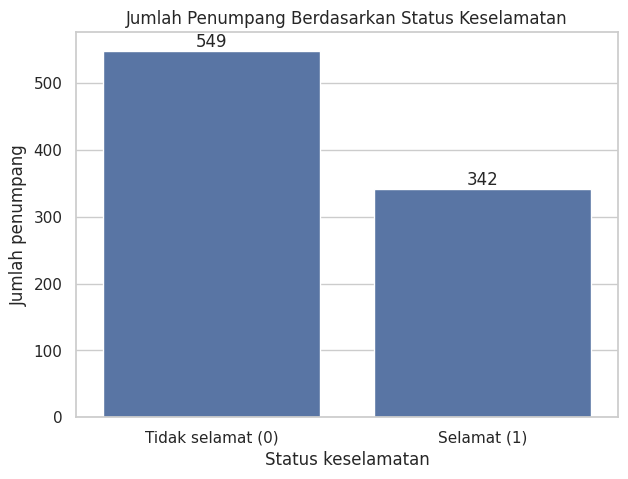

Persentase penumpang yang selamat: 38.38%


In [5]:
survival_counts = df["Survived"].value_counts().sort_index()
survival_labels = ["Tidak selamat (0)", "Selamat (1)"]

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="Survived")
ax.set_xticks([0, 1], survival_labels)
ax.set_title("Jumlah Penumpang Berdasarkan Status Keselamatan")
ax.set_xlabel("Status keselamatan")
ax.set_ylabel("Jumlah penumpang")

for container in ax.containers:
    ax.bar_label(container)
plt.show()

survival_rate = df["Survived"].mean() * 100
print(f"Persentase penumpang yang selamat: {survival_rate:.2f}%")

### 3.3 Distribusi fitur numerik

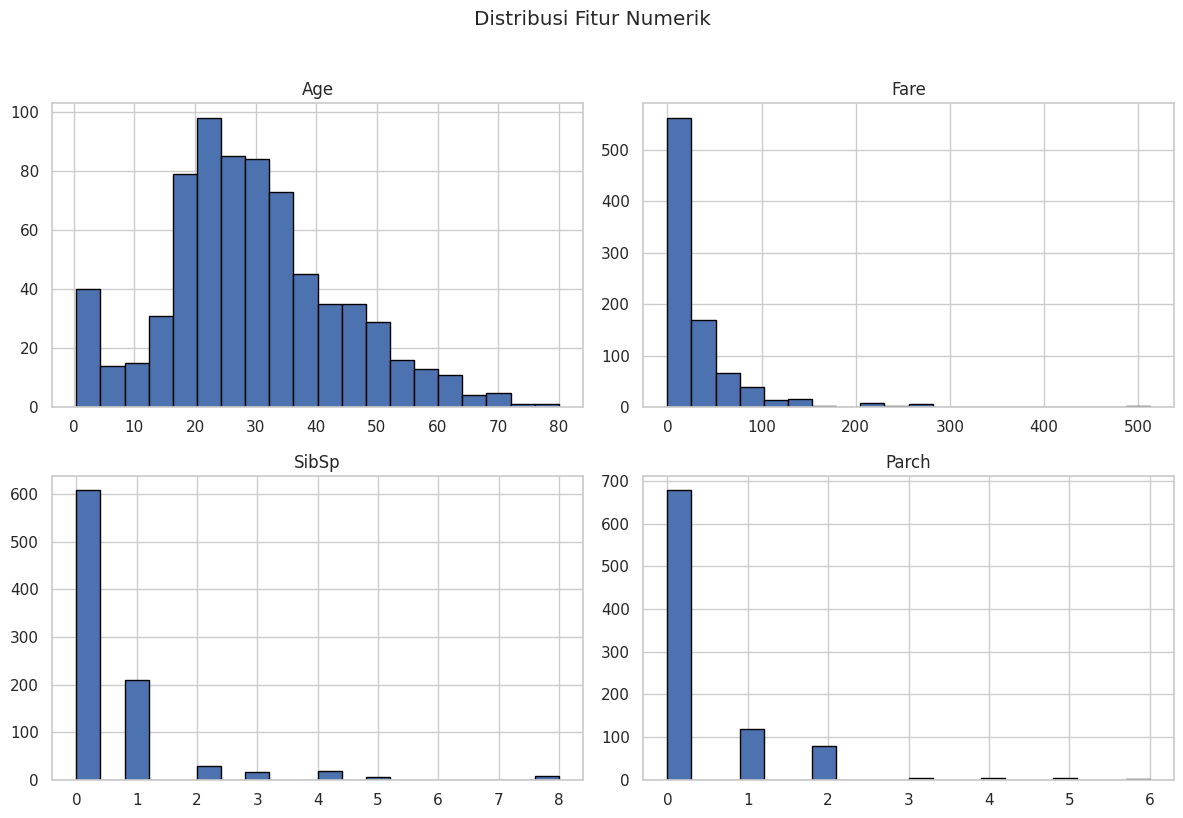

,count,mean,std,min,25%,50%,75%,max
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000


In [6]:
numeric_cols = [col for col in ["Age", "Fare", "SibSp", "Parch"] if col in df.columns]

df[numeric_cols].hist(bins=20, figsize=(12, 8), edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

display(df[numeric_cols].describe().T)

**Hal yang perlu diperhatikan:** distribusi `Age` menunjukkan rentang usia penumpang. `Fare` umumnya memiliki distribusi menceng ke kanan karena sebagian kecil penumpang membayar tarif jauh lebih tinggi. `SibSp` dan `Parch` menunjukkan jumlah anggota keluarga tertentu yang ikut dalam perjalanan.

### 3.4 Distribusi fitur kategorikal

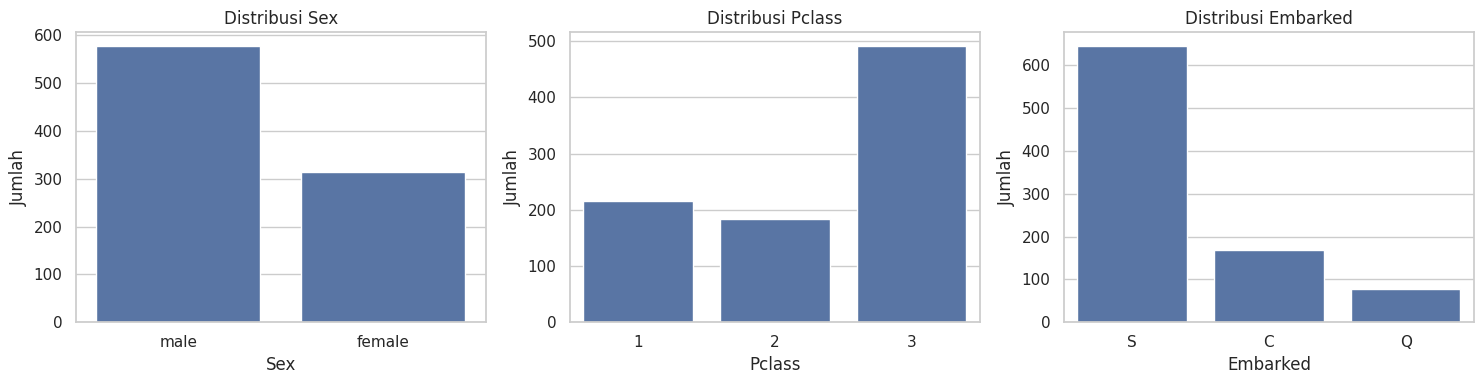

In [7]:
categorical_cols = [col for col in ["Sex", "Pclass", "Embarked"] if col in df.columns]

fig, axes = plt.subplots(1, len(categorical_cols), figsize=(15, 4))
if len(categorical_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Jumlah")

plt.tight_layout()
plt.show()

### 3.5 Hubungan jenis kelamin, kelas tiket, dan keselamatan

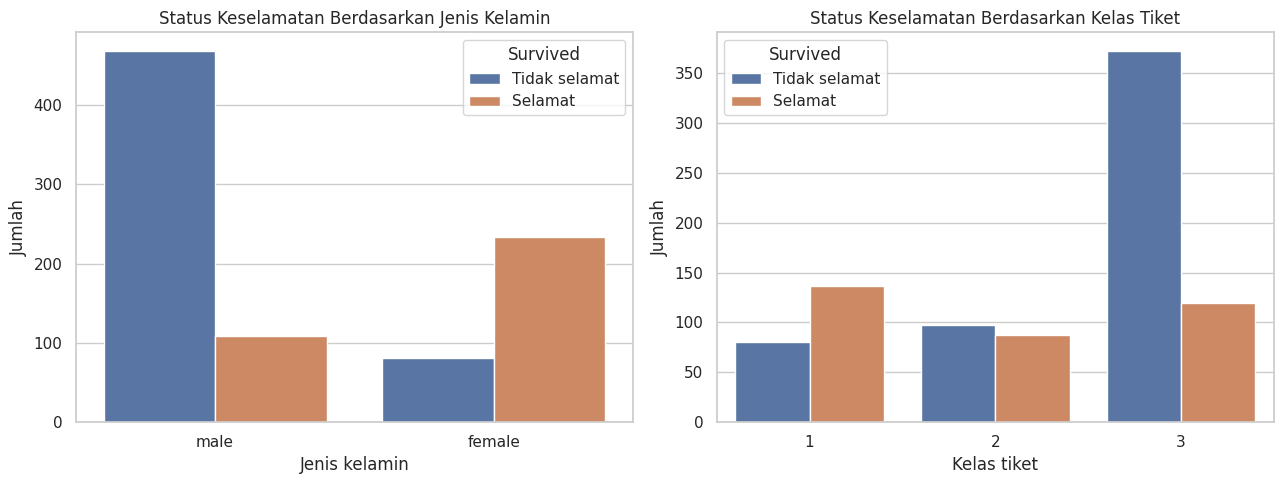

Tingkat keselamatan berdasarkan jenis kelamin (%):


,Survival Rate (%)
Sex,
female,74.20
male,18.89


Tingkat keselamatan berdasarkan kelas tiket (%):


,Survival Rate (%)
Pclass,
1,62.96
2,47.28
3,24.24


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x="Sex", hue="Survived", ax=axes[0])
axes[0].set_title("Status Keselamatan Berdasarkan Jenis Kelamin")
axes[0].set_xlabel("Jenis kelamin")
axes[0].set_ylabel("Jumlah")
axes[0].legend(title="Survived", labels=["Tidak selamat", "Selamat"])

sns.countplot(data=df, x="Pclass", hue="Survived", ax=axes[1])
axes[1].set_title("Status Keselamatan Berdasarkan Kelas Tiket")
axes[1].set_xlabel("Kelas tiket")
axes[1].set_ylabel("Jumlah")
axes[1].legend(title="Survived", labels=["Tidak selamat", "Selamat"])

plt.tight_layout()
plt.show()

print("Tingkat keselamatan berdasarkan jenis kelamin (%):")
display((df.groupby("Sex")["Survived"].mean() * 100).round(2).rename("Survival Rate (%)"))

print("Tingkat keselamatan berdasarkan kelas tiket (%):")
display((df.groupby("Pclass")["Survived"].mean() * 100).round(2).rename("Survival Rate (%)"))

### 3.6 Hubungan usia dan keselamatan

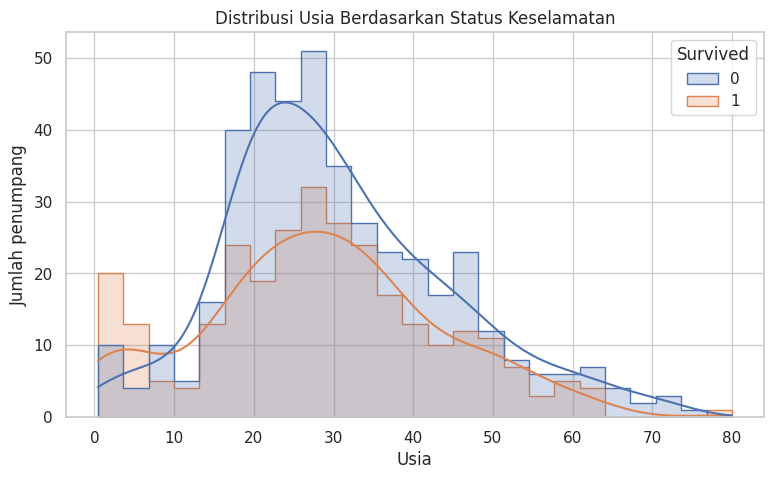

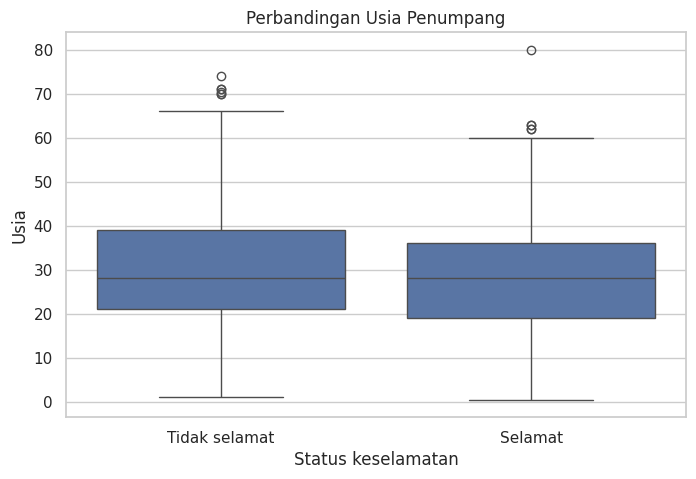

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,424.0,30.63,14.17,1.00,21.0,28.0,39.0,74.0
1,290.0,28.34,14.95,0.42,19.0,28.0,36.0,80.0


In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df, x="Age", hue="Survived",
    bins=25, kde=True, element="step",
    stat="count", common_norm=False
)
plt.title("Distribusi Usia Berdasarkan Status Keselamatan")
plt.xlabel("Usia")
plt.ylabel("Jumlah penumpang")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Survived", y="Age")
plt.xticks([0, 1], ["Tidak selamat", "Selamat"])
plt.title("Perbandingan Usia Penumpang")
plt.xlabel("Status keselamatan")
plt.ylabel("Usia")
plt.show()

display(df.groupby("Survived")["Age"].describe().round(2))

### 3.7 Hubungan tarif tiket dan keselamatan

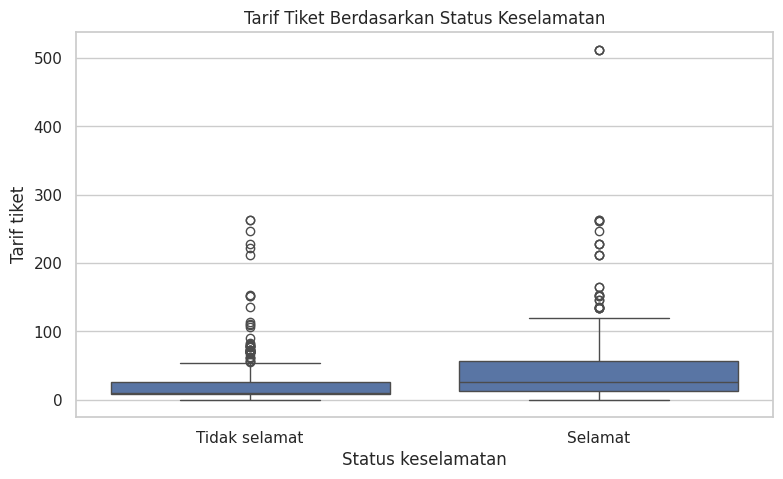

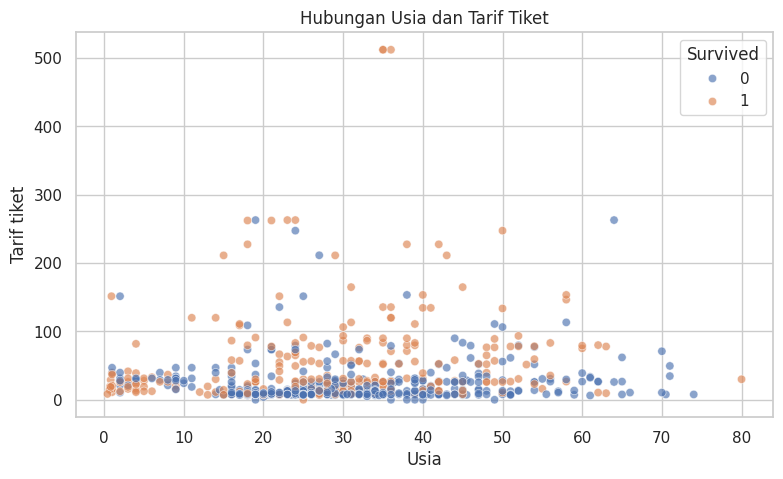

In [10]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Survived", y="Fare")
plt.xticks([0, 1], ["Tidak selamat", "Selamat"])
plt.title("Tarif Tiket Berdasarkan Status Keselamatan")
plt.xlabel("Status keselamatan")
plt.ylabel("Tarif tiket")
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="Survived", alpha=0.65)
plt.title("Hubungan Usia dan Tarif Tiket")
plt.xlabel("Usia")
plt.ylabel("Tarif tiket")
plt.show()

### 3.8 Korelasi antarfitur numerik

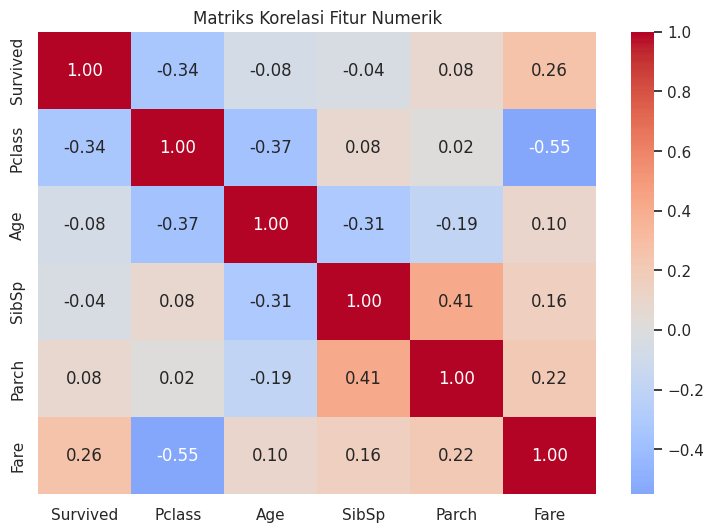

In [11]:
corr_cols = [c for c in ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"] if c in df.columns]
plt.figure(figsize=(9, 6))
sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriks Korelasi Fitur Numerik")
plt.show()

### 3.9 Ringkasan insight EDA
Cell ini menghasilkan ringkasan angka dari dataset yang sedang digunakan, sehingga kesimpulan tidak hanya bergantung pada pengamatan grafik.

In [12]:
print("RINGKASAN TEMUAN EDA")
print("-" * 55)

if "Sex" in df.columns:
    sex_rates = (df.groupby("Sex")["Survived"].mean() * 100).sort_values(ascending=False)
    print("\nSurvival rate berdasarkan jenis kelamin:")
    display(sex_rates.round(2))

if "Pclass" in df.columns:
    class_rates = (df.groupby("Pclass")["Survived"].mean() * 100).sort_index()
    print("\nSurvival rate berdasarkan kelas tiket:")
    display(class_rates.round(2))

if "Age" in df.columns:
    print(f"\\nMedian usia penumpang: {df['Age'].median():.2f} tahun")
if "Fare" in df.columns:
    print(f"Median tarif tiket: {df['Fare'].median():.2f}")
print(f"\\nTotal penumpang: {len(df)}")
print(f"Persentase selamat: {df['Survived'].mean() * 100:.2f}%")

RINGKASAN TEMUAN EDA
-------------------------------------------------------

Survival rate berdasarkan jenis kelamin:


,Survived
Sex,
female,74.20
male,18.89



Survival rate berdasarkan kelas tiket:


,Survived
Pclass,
1,62.96
2,47.28
3,24.24


\nMedian usia penumpang: 28.00 tahun
Median tarif tiket: 14.45
\nTotal penumpang: 891
Persentase selamat: 38.38%


**Insight yang dapat diambil:**

1. Jenis kelamin memiliki hubungan yang terlihat dengan keselamatan. Pada data Titanic, tingkat keselamatan penumpang perempuan jauh lebih tinggi dibandingkan laki-laki.
2. Kelas tiket juga berkaitan dengan keselamatan. Penumpang kelas pertama cenderung memiliki tingkat keselamatan lebih tinggi daripada kelas kedua dan ketiga.
3. Usia dan tarif tiket dapat memberikan informasi tambahan. Anak-anak dan penumpang dengan tarif lebih tinggi dapat menunjukkan pola keselamatan yang berbeda.
4. Fitur keluarga (`SibSp` dan `Parch`) berpotensi membantu model membedakan penumpang yang bepergian sendiri dan bersama keluarga.

Hubungan tersebut merupakan pola pada dataset, bukan bukti bahwa satu fitur secara langsung menyebabkan seseorang selamat.


## 4. Data Preprocessing

Sebelum preprocessing, data dipisahkan menjadi fitur (`X`) dan target (`y`). Selanjutnya data dibagi menjadi training set dan testing set. Proses imputasi, encoding, dan scaling dipelajari dari training set melalui pipeline agar informasi dari testing set tidak bocor ke proses pelatihan (*data leakage*).


### 4.1 Menentukan fitur dan target

In [13]:
# Salin dataset agar data asli tetap tersedia untuk EDA
data = df.copy()

# Pastikan target tersedia dan tidak kosong
data = data.dropna(subset=["Survived"]).copy()
data["Survived"] = data["Survived"].astype(int)

X = data.drop(columns=["Survived"])
y = data["Survived"]

print("Jumlah fitur awal:", X.shape[1])
print("Distribusi target:")
display(y.value_counts().rename(index={0: "Tidak selamat", 1: "Selamat"}))

Jumlah fitur awal: 11
Distribusi target:


,count
Survived,
Tidak selamat,549
Selamat,342


### 4.2 Feature engineering dan pemilihan kolom
`Name` digunakan untuk mengambil gelar penumpang (`Title`). `SibSp` dan `Parch` digabung menjadi `FamilySize`, lalu dibuat fitur `IsAlone`. Kolom identitas atau teks dengan variasi tinggi seperti `PassengerId`, `Ticket`, dan `Cabin` tidak digunakan langsung.

In [14]:
def create_features(frame):
    frame = frame.copy()

    # Jumlah anggota keluarga yang bepergian bersama penumpang
    if "SibSp" in frame.columns and "Parch" in frame.columns:
        frame["FamilySize"] = frame["SibSp"] + frame["Parch"] + 1
        frame["IsAlone"] = (frame["FamilySize"] == 1).astype(int)

    # Mengambil gelar dari nama, jika kolom Name tersedia
    if "Name" in frame.columns:
        frame["Title"] = frame["Name"].str.extract(r",\s*([^.]*)\.", expand=False)
        frame["Title"] = frame["Title"].str.strip()

        # Menggabungkan gelar yang jarang muncul agar kategori tidak terlalu banyak
        common_titles = ["Mr", "Miss", "Mrs", "Master"]
        frame["Title"] = frame["Title"].where(frame["Title"].isin(common_titles), "Other")

    # Kolom berikut tidak dipakai sebagai prediktor langsung
    drop_cols = [c for c in ["PassengerId", "Name", "Ticket", "Cabin"] if c in frame.columns]
    frame = frame.drop(columns=drop_cols)

    return frame

X_base = X.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore")
X = create_features(X)

print("Ukuran fitur setelah feature engineering:", X.shape)
display(X.head())
print("\nTipe data:")
display(X.dtypes)

Ukuran fitur setelah feature engineering: (891, 10)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
0,3,male,22.0,1,0,7.2500,S,2,0,Mr
1,1,female,38.0,1,0,71.2833,C,2,0,Mrs
2,3,female,26.0,0,0,7.9250,S,1,1,Miss
3,1,female,35.0,1,0,53.1000,S,2,0,Mrs
4,3,male,35.0,0,0,8.0500,S,1,1,Mr



Tipe data:


,0
Pclass,int64
Sex,object
Age,float64
SibSp,int64
Parch,int64
Fare,float64
Embarked,object
FamilySize,int64
IsAlone,int64
Title,object


### 4.3 Membagi training dan testing set

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])

print("\nProporsi target pada training set:")
display(y_train.value_counts(normalize=True).sort_index().round(3))

print("Proporsi target pada testing set:")
display(y_test.value_counts(normalize=True).sort_index().round(3))

Jumlah data training: 712
Jumlah data testing : 179

Proporsi target pada training set:


,proportion
Survived,
0,0.617
1,0.383


Proporsi target pada testing set:


,proportion
Survived,
0,0.615
1,0.385


### 4.4 Menangani missing values

Strategi yang digunakan:
- **Numerik:** nilai kosong diisi dengan median. Median lebih tahan terhadap nilai ekstrem dibandingkan mean.
- **Kategorikal:** nilai kosong diisi dengan modus (kategori yang paling sering muncul).
- **Cabin:** tidak dipakai sebagai fitur langsung karena jumlah nilai kosongnya sangat besar. Informasi `Cabin` dapat dieksplorasi lebih lanjut, tetapi pada tugas ini kolom tersebut dihapus agar preprocessing lebih sederhana dan konsisten.

Imputer ditempatkan di dalam pipeline sehingga nilai pengganti dihitung hanya dari training set.


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identifikasi kolom numerik dan kategorikal berdasarkan training set
numeric_features = [c for c in X_train.select_dtypes(include=["number"]) if c != "Pclass"]
categorical_features = [c for c in X_train.columns if c not in numeric_features]

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("\nPipeline preprocessing berhasil dibuat.")

Fitur numerik: ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Fitur kategorikal: ['Pclass', 'Sex', 'Embarked', 'Title']

Pipeline preprocessing berhasil dibuat.


### 4.5 Encoding fitur kategorikal

Metode yang digunakan adalah **One-Hot Encoding**. Metode ini mengubah kategori seperti `Sex`, `Embarked`, `Pclass`, dan `Title` menjadi kolom indikator 0/1. One-Hot Encoding dipilih karena kategori tersebut tidak memiliki urutan numerik yang konsisten untuk sebagian besar fitur. Untuk `Pclass`, meskipun kelas memiliki urutan, One-Hot Encoding tetap digunakan agar model tidak mengasumsikan jarak antar kelas sama.

`handle_unknown="ignore"` membuat pipeline tetap dapat memproses kategori baru yang mungkin muncul pada data lain.


### 4.6 Normalisasi / standardisasi fitur numerik

Fitur numerik distandardisasi menggunakan `StandardScaler`, sehingga setiap fitur memiliki rata-rata mendekati 0 dan standar deviasi mendekati 1 pada data training. Hal ini membantu algoritma seperti Logistic Regression yang sensitif terhadap skala fitur. Standardisasi tidak wajib untuk semua algoritma, misalnya Decision Tree, tetapi digunakan di sini agar preprocessing siap untuk model linear.


### 4.7 Menjalankan preprocessing

In [17]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Nama kolom setelah encoding
feature_names = preprocessor.get_feature_names_out()

print("Ukuran data training setelah preprocessing:", X_train_processed.shape)
print("Ukuran data testing setelah preprocessing :", X_test_processed.shape)
print("Jumlah fitur setelah encoding:", len(feature_names))

# Tampilkan beberapa baris hasil preprocessing
processed_preview = pd.DataFrame(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    columns=feature_names,
    index=X_train.index
)
display(processed_preview.head())

Ukuran data training setelah preprocessing: (712, 19)
Ukuran data testing setelah preprocessing : (179, 19)
Jumlah fitur setelah encoding: 19


,num__Age,num__SibSp,num__Parch,num__Fare,num__FamilySize,num__IsAlone,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,cat__Sex_female,cat__Sex_male,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S,cat__Title_Master,cat__Title_Miss,cat__Title_Mr,cat__Title_Mrs,cat__Title_Other
692,-0.081135,-0.465084,-0.466183,0.513812,-0.556339,0.800346,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
481,-0.081135,-0.465084,-0.466183,-0.662563,-0.556339,0.800346,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
527,-0.081135,-0.465084,-0.466183,3.955399,-0.556339,0.800346,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
855,-0.887827,-0.465084,0.727782,-0.467874,0.073412,-1.249460,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
801,0.110934,0.478335,0.727782,-0.115977,0.703162,-1.249460,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


### 4.8 Memastikan tidak ada missing values setelah preprocessing

In [18]:
train_missing = np.isnan(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed
).sum()

test_missing = np.isnan(
    X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed
).sum()

print("Missing value pada training setelah preprocessing:", train_missing)
print("Missing value pada testing setelah preprocessing :", test_missing)

Missing value pada training setelah preprocessing: 0
Missing value pada testing setelah preprocessing : 0


## 5. Baseline vs Feature Engineering

- **Baseline:** Pclass, Sex, Age, SibSp, Parch, Fare, dan Embarked.
- **Feature Engineering:** fitur baseline ditambah FamilySize, IsAlone, dan Title.

Kedua model memakai Logistic Regression dengan pengaturan yang sama dan baris train/test yang sama (80/20, stratifikasi, seed 42). Pipeline masing-masing mempelajari imputasi, standardisasi, dan encoding dari train. Perbandingan memakai accuracy, precision macro, recall macro, dan F1 macro.


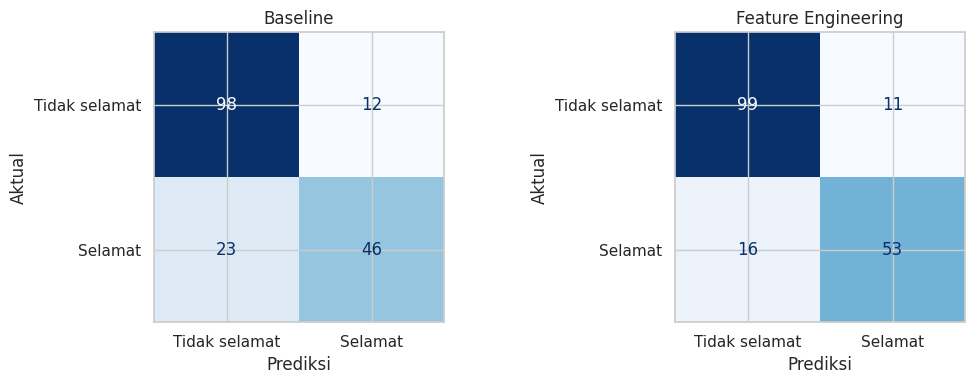

,Accuracy,Precision macro,Recall macro,F1 macro
Baseline,0.8045,0.8015,0.7788,0.7864
Feature Engineering,0.8492,0.8445,0.8341,0.8385


,Selisih FE − Baseline (poin persentase)
Accuracy,4.47
Precision macro,4.30
Recall macro,5.53
F1 macro,5.20


In [19]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay,
)

base_preprocessor = ColumnTransformer([
    ("num", clone(numeric_transformer), [c for c in numeric_features if c in X_base]),
    ("cat", clone(categorical_transformer), [c for c in categorical_features if c in X_base]),
])

experiments = {
    "Baseline": (X_base, base_preprocessor),
    "Feature Engineering": (X, preprocessor),
}
scores = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, (features, prep)) in zip(axes, experiments.items()):
    model = Pipeline([
        ("preprocessing", clone(prep)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ])
    model.fit(features.loc[X_train.index], y_train)
    predicted = model.predict(features.loc[X_test.index])
    scores[name] = {
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision macro": precision_score(y_test, predicted, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, predicted, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, predicted, average="macro", zero_division=0),
    }
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1],
        display_labels=["Tidak selamat", "Selamat"], cmap="Blues",
        colorbar=False, ax=ax,
    )
    ax.set(title=name, xlabel="Prediksi", ylabel="Aktual")

plt.tight_layout()
plt.show()

comparison = pd.DataFrame.from_dict(scores, orient="index")
delta_pp = 100 * (comparison.loc["Feature Engineering"] - comparison.loc["Baseline"])
display(comparison.round(4))
display(delta_pp.round(2).rename("Selisih FE − Baseline (poin persentase)").to_frame())


## 6. Kesimpulan

EDA memperlihatkan perbedaan tingkat keselamatan menurut jenis kelamin dan kelas tiket. Perbandingan berikut membaca hasil aktual kedua model pada test set yang sama. Selisih ini menggambarkan hasil pada pembagian data yang digunakan.


In [20]:
change = delta_pp["F1 macro"]
if np.isclose(change, 0):
    print("F1 macro sama pada test set ini.")
elif change > 0:
    print(f"Feature engineering menaikkan F1 macro sebesar {change:.2f} poin persentase.")
else:
    print(f"Feature engineering menurunkan F1 macro sebesar {-change:.2f} poin persentase.")


Feature engineering menaikkan F1 macro sebesar 5.20 poin persentase.


## 7. Catatan

- Jalankan notebook dari cell pertama sampai terakhir agar semua variabel terbentuk dengan benar.
- Jika ingin memakai file Kaggle asli, letakkan `train.csv` pada folder yang sama dengan notebook sebelum menjalankan cell pemuatan data.
- Nilai evaluasi model dapat berubah jika pembagian data atau metode yang digunakan diubah.
- Untuk pengembangan berikutnya, beberapa pendekatan lain dapat dibandingkan, misalnya Random Forest, Decision Tree, atau Gradient Boosting.
